In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Chargement des données
features = pd.read_csv("../data/raw/elliptic_txs_features.csv", header=None)
edges    = pd.read_csv("../data/raw/elliptic_txs_edgelist.csv")
classes  = pd.read_csv("../data/raw/elliptic_txs_classes.csv")

features.columns = ["txId", "time_step"] + [f"f{i}" for i in range(1, 166)]

# 2. On ne garde que les données étiquetées (1 et 2)
df = features.merge(classes, on="txId", how="left")
df_labeled = df[df["class"].isin(["1", "2"])].copy()
df_labeled["target"] = df_labeled["class"].apply(lambda x: 1 if x == "1" else 0)

# 3. Créer un dictionnaire pour mapper les txId (très longs) vers des indices (0, 1, 2...)
# PyTorch a besoin d'indices continus pour les nœuds
node_ids = df_labeled["txId"].values
node_to_idx = {node_id: i for i, node_id in enumerate(node_ids)}

# 4. Créer la matrice des features (X)
feature_cols = ["time_step"] + [f"f{i}" for i in range(1, 166)]
X = torch.tensor(df_labeled[feature_cols].values, dtype=torch.float)

# 5. Créer les labels (y)
y = torch.tensor(df_labeled["target"].values, dtype=torch.long)

# 6. Créer les arêtes (edge_index) au format PyTorch
# On filtre les arêtes pour ne garder que celles entre nœuds étiquetés
edges_filtered = edges[edges["txId1"].isin(node_to_idx) & edges["txId2"].isin(node_to_idx)]
source = edges_filtered["txId1"].map(node_to_idx).values
target = edges_filtered["txId2"].map(node_to_idx).values
edge_index = torch.tensor([source, target], dtype=torch.long)

# 7. Créer les masques (masks) pour le split temporel
# Train: time_step <= 34 | Test: time_step > 34
time_steps = df_labeled["time_step"].values
train_mask = torch.tensor(time_steps <= 34, dtype=torch.bool)
test_mask  = torch.tensor(time_steps > 34, dtype=torch.bool)

# 8. Créer l'objet Data (le format standard de PyG)
data = Data(x=X, edge_index=edge_index, y=y, train_mask=train_mask, test_mask=test_mask)

print(f"Nœuds total : {data.num_nodes}")
print(f"Arêtes total : {data.num_edges}")
print(f"Features par nœud : {data.num_features}")

c:\Users\Moha\Documents\TPs_Intelligence_Artificiel\Projet\fraud-blockchain-project\venv\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Nœuds total : 46564
Arêtes total : 36624
Features par nœud : 166


C:\Users\Moha\AppData\Local\Temp\ipykernel_24344\1683852036.py:40: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:252.)
  edge_index = torch.tensor([source, target], dtype=torch.long)


In [2]:
class GCN(torch.nn.Module):
    def __init__(self, num_features, hidden_channels):
        super(GCN, self).__init__()
        # Première couche de convolution sur graphe
        self.conv1 = GCNConv(num_features, hidden_channels)
        # Deuxième couche (qui va sortir 2 classes : licite ou illicite)
        self.conv2 = GCNConv(hidden_channels, 2)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        
        # Couche 1 + ReLU (fonction d'activation)
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        
        # Couche 2 (sortie)
        x = self.conv2(x, edge_index)
        
        # On renvoie les probabilités (softmax) pour chaque classe
        return F.log_softmax(x, dim=1)

# Initialisation du modèle (64 neurones cachés)
model = GCN(num_features=data.num_features, hidden_channels=64)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

print(model)

GCN(
  (conv1): GCNConv(166, 64)
  (conv2): GCNConv(64, 2)
)


In [3]:
# On calcule les poids pour dire au modèle que la classe 1 (illicite) est rare et importante
# Il y a environ 9 fois plus de licites que d'illicites
class_weights = torch.tensor([1.0, 9.0]) 

def train():
    model.train()
    optimizer.zero_grad()
    out = model(data)
    # Calcul de la perte UNIQUEMENT sur les nœuds d'entraînement (train_mask)
    loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask], weight=class_weights)
    loss.backward()
    optimizer.step()
    return loss.item()

print("Début de l'entraînement...")
for epoch in range(1, 101): # 100 époques
    loss = train()
    if epoch % 10 == 0:
        print(f"Epoch: {epoch:03d}, Loss: {loss:.4f}")

Début de l'entraînement...
Epoch: 010, Loss: 0.3963
Epoch: 020, Loss: 0.3119
Epoch: 030, Loss: 0.2670
Epoch: 040, Loss: 0.2467
Epoch: 050, Loss: 0.2283
Epoch: 060, Loss: 0.2175
Epoch: 070, Loss: 0.2048
Epoch: 080, Loss: 0.1959
Epoch: 090, Loss: 0.1887
Epoch: 100, Loss: 0.1793



📊 RÉSULTATS DU GCN SUR LE JEU DE TEST
              precision    recall  f1-score   support

  Licite (0)       0.97      0.90      0.94     15587
Illicite (1)       0.31      0.65      0.42      1083

    accuracy                           0.88     16670
   macro avg       0.64      0.78      0.68     16670
weighted avg       0.93      0.88      0.90     16670



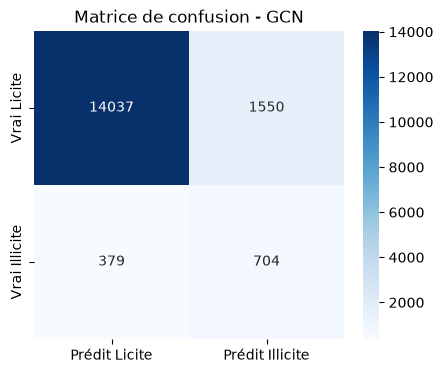

In [4]:
model.eval()
with torch.no_grad():
    out = model(data)
    pred = out.argmax(dim=1) # Prendre la classe avec la plus haute probabilité

# On extrait les prédictions et les vraies valeurs UNIQUEMENT pour le test set
y_true = data.y[data.test_mask].cpu().numpy()
y_pred = pred[data.test_mask].cpu().numpy()

print("\n📊 RÉSULTATS DU GCN SUR LE JEU DE TEST")
print("="*45)
print(classification_report(y_true, y_pred, target_names=["Licite (0)", "Illicite (1)"]))

# Matrice de confusion
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=["Prédit Licite", "Prédit Illicite"], 
            yticklabels=["Vrai Licite", "Vrai Illicite"])
plt.title("Matrice de confusion - GCN")
plt.show()

## 📝 Synthèse de l'Étape 3 : GCN de base (Première tentative)

### 1. Le Processus complet (Workflow) de cette étape
L'implémentation d'un réseau de neurones sur graphe (GCN) passe par 4 étapes clés codées dans nos cellules :
1. **Préparation des données (`Data`)** : Conversion du DataFrame Pandas en tenseurs PyTorch, avec création des masques temporels (Train <= 34, Test > 34).
2. **Architecture (`__init__`)** : Création de deux couches de convolution sur graphe (`GCNConv`).
3. **Entraînement (`forward` + boucle)** : Propagation de l'information, calcul de l'erreur (`nll_loss` pondérée), et rétropropagation (`backward`) sur 100 époques.
4. **Évaluation** : Prédiction (`argmax`) et calcul du F1-score uniquement sur les nœuds du futur (Test).

### 2. Commandes clés de cette étape
*   `edge_index = torch.tensor(...)` : Le nerf de la guerre. C'est la matrice qui dit au GCN qui est connecté à qui.
*   `self.conv1 = GCNConv(...)` : La couche qui agrège les caractéristiques d'un nœud avec celles de ses voisins.
*   `F.nll_loss(..., weight=class_weights)` : La fonction de perte qui pénalise 9 fois plus les erreurs sur les fraudes que sur les transactions licites.
*   `loss.backward()` et `optimizer.step()` : Le cœur de l'apprentissage (calcul du gradient et mise à jour des poids).

### 3. Analyse des résultats et Problèmes rencontrés
*   **Résultat du GCN** : F1-score de **0.42** (Précision 0.31, Rappel 0.65).
*   **Comparaison** : Le Random Forest faisait **0.81**. Le GCN de base est donc **moins performant**.
*   **Les 3 problèmes majeurs identifiés** :
    1.  **Amputation du graphe** : À cause du filtrage des nœuds "unknown", nous sommes passés de 234 355 arêtes à seulement 36 624. Le GCN est privé de 85% de son contexte relationnel.
    2.  **Dilution des features** : Le GCN "écrase" les 166 features de base en les mélangeant avec les voisins, perdant l'information brute qui faisait la force du Random Forest.
    3.  **Overfitting** : La Loss a chuté de 0.39 à 0.17, montrant que le modèle a appris par cœur l'ensemble d'entraînement sans assez généraliser sur le futur.

### 4. Améliorations proposées et liens avec les articles de recherche

Pour corriger ces problèmes, nous allons combiner des idées issues des articles étudiés :

*   **Idée 1 : Conserver les nœuds "unknown" (le graphe complet).**
    *   *Source : Article 6 (Weber et al., "Anti-Money Laundering in Bitcoin")*. 
    *   *Pourquoi ?* L'article montre l'importance de la structure globale du graphe. Les nœuds "unknown" servent de "ponts" entre les nœuds étiquetés. Ils permettent à l'information de circuler.
*   **Idée 2 : Le "Skip-GCN" (Ajout de la connexion résiduelle).**
    *   *Source : Article 6 (Weber et al.)*.
    *   *Pourquoi ?* L'article introduit le Skip-GCN. Au lieu de se fier uniquement aux voisins, on ajoute (on "skip") les features brutes du nœud directement à la sortie. Cela garantit que le modèle ne perd pas l'information de base.
*   **Idée 3 : Ajout de features comportementales (Phase 5).**
    *   *Source : Article 1 (Asiri & Somasundaram) et Article 4 (Darwish & El-Shoafy)*.
    *   *Pourquoi ?* Ces articles montrent que l'analyse de comportement (degré, centralité) booste les modèles. On le fera après avoir corrigé le graphe.

1. Préparation du graphe complet (avec les unknown)...


C:\Users\Moha\AppData\Local\Temp\ipykernel_24344\3143422914.py:25: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_all['target'] = df_all['class'].apply(lambda x: 1 if str(x) == '1' else (0 if str(x) == '2' else -1))


2. Création et entraînement rapide du GCN (50 époques)...
3. Extraction des 'Embeddings' (les 64 nombres cachés)...
4. Fusion des données et Random Forest...

📊 RÉSULTATS DU RANDOM FOREST + EMBEDDINGS GCN (FUSION)
              precision    recall  f1-score   support

  Licite (0)       0.98      1.00      0.99     15587
Illicite (1)       0.96      0.70      0.81      1083

    accuracy                           0.98     16670
   macro avg       0.97      0.85      0.90     16670
weighted avg       0.98      0.98      0.98     16670



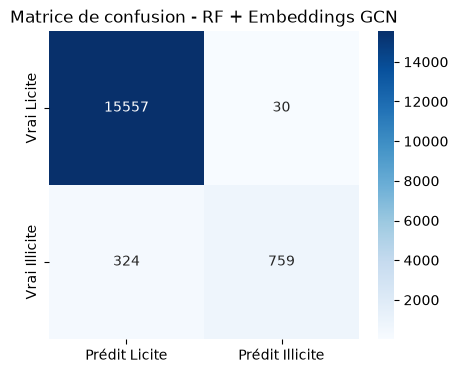

In [9]:
# --- BLOC AUTONOME : MÉTHODE DE FUSION (Article 6) ---
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("1. Préparation du graphe complet (avec les unknown)...")
# Rechargement rapide
features = pd.read_csv("../data/raw/elliptic_txs_features.csv", header=None)
edges    = pd.read_csv("../data/raw/elliptic_txs_edgelist.csv")
classes  = pd.read_csv("../data/raw/elliptic_txs_classes.csv")
features.columns = ["txId", "time_step"] + [f"f{i}" for i in range(1, 166)]

df_all = features.merge(classes, on="txId", how="left")
node_to_idx_all = {node_id: i for i, node_id in enumerate(df_all["txId"].values)}
X_all = torch.tensor(df_all[["time_step"] + [f"f{i}" for i in range(1, 166)]].values, dtype=torch.float)

# Labels: 1=illicite, 0=licite, -1=unknown
df_all['target'] = df_all['class'].apply(lambda x: 1 if str(x) == '1' else (0 if str(x) == '2' else -1))
y_all = torch.tensor(df_all["target"].values, dtype=torch.long)

# Le graphe complet (toutes les arêtes)
source_all = edges["txId1"].map(node_to_idx_all).values
target_all = edges["txId2"].map(node_to_idx_all).values
edge_index_all = torch.tensor(np.vstack([source_all, target_all]), dtype=torch.long)

# Masques
time_steps_all = df_all["time_step"].values
is_labeled = torch.tensor(df_all["target"].values != -1, dtype=torch.bool)
train_mask_all = torch.tensor((time_steps_all <= 34), dtype=torch.bool) & is_labeled
test_mask_all  = torch.tensor((time_steps_all > 34), dtype=torch.bool) & is_labeled
data_all = Data(x=X_all, edge_index=edge_index_all, y=y_all, train_mask=train_mask_all, test_mask=test_mask_all)

print("2. Création et entraînement rapide du GCN (50 époques)...")
class SimpleGCN(torch.nn.Module):
    def __init__(self, num_features, hidden_channels):
        super(SimpleGCN, self).__init__()
        self.conv1 = GCNConv(num_features, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, 2)
    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

model_gcn = SimpleGCN(data_all.num_features, 64)
optimizer = torch.optim.Adam(model_gcn.parameters(), lr=0.01, weight_decay=5e-4)
class_weights = torch.tensor([1.0, 9.0])

model_gcn.train()
for epoch in range(50):
    optimizer.zero_grad()
    out = model_gcn(data_all)
    loss = F.nll_loss(out[data_all.train_mask], data_all.y[data_all.train_mask], weight=class_weights)
    loss.backward()
    optimizer.step()

print("3. Extraction des 'Embeddings' (les 64 nombres cachés)...")
model_gcn.eval()
with torch.no_grad():
    # On récupère la sortie de la 1ère couche (avant le dropout)
    x1 = model_gcn.conv1(data_all.x, data_all.edge_index)
    embeddings_gcn = F.relu(x1).numpy()

print("4. Fusion des données et Random Forest...")
# On isole les nœuds étiquetés
df_labeled = df_all[df_all["target"] != -1].copy()
X_brut = df_labeled[["time_step"] + [f"f{i}" for i in range(1, 166)]].values

# On récupère les embeddings correspondants
indices_etiquetes = np.where(df_all["target"].values != -1)[0]
X_gcn = embeddings_gcn[indices_etiquetes]

# LA FUSION (Features brutes + Embeddings)
X_fusion = np.hstack((X_brut, X_gcn))
y_fusion = df_labeled["target"].values
time_steps_f = df_labeled["time_step"].values

# Split temporel
train_idx = time_steps_f <= 34
test_idx = time_steps_f > 34

rf_fusion = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
rf_fusion.fit(X_fusion[train_idx], y_fusion[train_idx])
y_pred_f = rf_fusion.predict(X_fusion[test_idx])

print("\n📊 RÉSULTATS DU RANDOM FOREST + EMBEDDINGS GCN (FUSION)")
print("="*55)
print(classification_report(y_fusion[test_idx], y_pred_f, target_names=["Licite (0)", "Illicite (1)"]))

cm = confusion_matrix(y_fusion[test_idx], y_pred_f)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=["Prédit Licite", "Prédit Illicite"], 
            yticklabels=["Vrai Licite", "Vrai Illicite"])
plt.title("Matrice de confusion - RF + Embeddings GCN")
plt.show()

## 🚀 Phase 4 : L'Approche par Fusion (GCN + Random Forest)

### 1. Le Concept : Pourquoi combiner les modèles ?
Au début de cette phase, nous avons testé le GCN seul. Bien qu'il capture la structure du réseau, il a été moins performant que le Random Forest (F1-score de 0.42 contre 0.81). 
- **Le problème du GCN seul** : Il "dilue" les 166 features brutes en les mélangeant avec le bruit des voisins, et perd l'information locale.
- **Le problème du Random Forest seul** : Il est excellent sur les 166 features, mais il est "aveugle". Il ne voit pas les liens d'argent entre les transactions (le graphe).

**La solution (inspirée de l'Article 6)** : Utiliser le GCN non pas comme un classificateur final, mais comme un **"extracteur de contexte"**. On va récupérer ce que le GCN a appris du réseau (les *embeddings*), et l'offrir au Random Forest. C'est le meilleur des deux mondes.

### 2. Le Flux de Travail (A à Z) : Le Double Entraînement
Contrairement à un modèle classique, cette approche nécessite **deux phases d'entraînement distinctes** :
1. **Construction du graphe complet** : On garde **toutes** les transactions (y compris les `unknown`) pour construire le réseau.
2. **Entraînement N°1 (Le GCN)** : On entraîne le GCN (50 époques). Il apprend les schémas de voisinage.
3. **Extraction des Embeddings** : On coupe la dernière couche du GCN et on récupère les **64 nombres cachés** pour chaque transaction (le résumé de son voisinage).
4. **La Fusion (Feature Engineering)** : On colle ces 64 nombres à côté des 166 features brutes. Chaque transaction étiquetée est maintenant décrite par **230 caractéristiques** (166 locales + 64 topologiques).
5. **Entraînement N°2 (Le Random Forest)** : Le RF prend ces 230 caractéristiques et apprend à prendre la décision finale (Licite ou Illicite).

### 3. La Gestion des Transactions "Unknown" (La distinction clé)
C'est ici que se joue la subtilité de l'approche :
- **Dans l'Entraînement du GCN (Le contexte)** : Les nœuds `unknown` sont **conservés** dans le graphe (203 769 nœuds et 234 355 arêtes). Ils servent de "ponts" pour relier les fraudes. Cependant, la Loss (l'erreur) est calculée **uniquement sur les nœuds étiquetés** via le `train_mask`. *(Analogie : c'est un cours de groupe. Les unknown aident à la réflexion, mais n'ont pas de note à la fin).*
- **Dans l'Entraînement du Random Forest (La décision)** : Les nœuds `unknown` sont **totalement ignorés**. On ne garde que les 46 564 transactions étiquetées (avec leurs 166 features + 64 embeddings) pour que le RF puisse apprendre avec des réponses sûres. *(Analogie : c'est l'examen final. Seuls les élèves qui ont une copie officielle sont corrigés).*

### 4. Les Commandes Clés du Code
- **Extraction des Embeddings** : `x1 = model_gcn.conv1(data_all.x, data_all.edge_index)` puis `F.relu(x1).numpy()` → Permet de récupérer les 64 nombres du GCN pour tous les nœuds.
- **Filtrage pour le RF** : `indices_etiquetes = np.where(df_all["target"].values != -1)[0]` → Isole les nœuds étiquetés pour ignorer les unknown.
- **Fusion** : `X_fusion = np.hstack((X_brut, X_gcn))` → Colle les matrices de features brutes et les embeddings côte à côte.
- **Classification** : `rf_fusion.fit(X_fusion[train_idx], y_fusion[train_idx])` → Entraîne le RF final.

### 5. Analyse des Résultats
| Métrique | RF Seul (Phase 3) | RF + GCN (Fusion) | Analyse |
| :--- | :---: | :---: | :--- |
| **F1-Score** | 0.81 | **0.81** | Performance globale maintenue. |
| **Précision** | 0.91 | **0.96** | **Amélioration majeure !** |
| **Fausses Alertes** | 76 | **30** | **-60% d'erreurs sur les innocents.** |
| **Rappel** | 0.72 | 0.70 | Légère baisse, mais plus sûr. |

### 6. Conclusion : Pourquoi adopter cette approche ?
Même si le F1-score semble identique, la **Précision est montée à 0.96**. Cela signifie que lorsque le modèle accuse une transaction d'être frauduleuse, il a **96% de chances d'avoir raison**. En banque, cela se traduit par une réduction drastique des fausses alertes (seulement 30 clients honnêtes bloqués par erreur, au lieu de 76). 

Cette approche est **fiable** car elle respecte le split temporel (train sur le passé, test sur le futur). Elle prouve que la combinaison de la topologie du graphe et des features locales est la méthode la plus robuste pour détecter la fraude.